# 07 · SPY: a full replication of the SPX protocol (plan §16.3)

**What changes for SPY.**
- **The options are American** and settle into shares. Puts are priced on Lecture 12's tree (150 steps, control variate), with δ, ν, vanna and theta from finite differences on the same tree. Calls are priced as European, as the lecture does.
- **SPY pays quarterly dividends.** The distribution enters the hedge leg on ex-dates.
- **The index level is SPY's close:** Nasdaq's from 2016-11-03, and before that Stooq's, with its dividend adjustment reversed (checked against Nasdaq on 1,821 sessions: median 0.43 bp in level, 0.14 bp in return).
- **The dividend yield** comes from SPX's implied carry, using the SPX close on the few sessions without SPX's options-implied level (plan §15).

**What is the same:** every SPX procedure that applies.
- the rehearsal and its specification checks on 2018–2019;
- R8's tuning on 2019, and the dry run;
- 2020 with every Table 8.1 variant except A (American parity gives no options-implied level), and the verdict table;
- the 2011–2023 walk-forward.

**Status.** SPY's 2020 Gains for R0–R5 were first computed on 2026-11-04, so this 2020 verdict is post hoc. The clean evidence is the untouched SPY years: 2011–2014, 2017 and 2021–2023 (`results/spy/year_ledger_spy.csv`).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
pd.read_csv(R / "spy/year_ledger_spy.csv")

,years,exposure,date,run
0,2010,fit-only (walk-forward's first windows); tuned...,2026-11-05,scripts/tune_r8.py --spy 2010; scripts/run_wal...
1,2011-2014,"evaluated: the walk-forward, clean held-out",2026-11-05,scripts/run_walkforward.py --spy; scripts/run_...
2,2015-2016,tuned: R8 for test months from 2017-01; evalua...,2026-11-05,scripts/tune_r8.py --spy 2015 2016
3,2017,"evaluated: the walk-forward, clean held-out",2026-11-05,scripts/run_walkforward.py --spy
4,2018,evaluated: rehearsal 2018-07 to 12 (6-month wi...,2026-11-05,scripts/run_rehearsal.py --spy
5,2019,fit-only for §16.1 (2026-11-04); evaluated: re...,2026-11-05,scripts/run_rehearsal.py --spy; scripts/tune_r...
6,2020,"evaluated: §16.1 R0-R5 (2026-11-04), so the §1...",2026-11-04 and 2026-11-05,scripts/run_spy.py; scripts/run_test_year.py 2...
7,2021-2023,"evaluated: the walk-forward, clean held-out",2026-11-05,scripts/run_walkforward.py --spy


## The rehearsal's specification checks (2018 and 2019)

In [3]:
pd.concat([pd.read_csv(R / f"spy/rehearsal/spec_checks_{y}.csv").assign(year=y) for y in (2018, 2019)]).round(4)

,cp,check,gain,lo,p_adj,contradicts,year
0,C,degree 3 vs 2,0.0049,-0.0023,0.1136,False,2018
1,C,alpha:0 vs alpha:0.5,0.0099,-0.0739,0.8965,False,2018
2,C,alpha:0.25 vs alpha:0.5,0.0007,-0.0425,0.8965,False,2018
3,C,alpha:0.75 vs alpha:0.5,0.0078,-0.0098,0.6287,False,2018
4,C,alpha:1 vs alpha:0.5,0.0169,-0.0024,0.1888,False,2018
5,P,degree 3 vs 2,0.0162,-0.0015,0.0604,False,2018
6,P,alpha:0 vs alpha:0.5,-0.1351,-0.2175,1.0000,False,2018
7,P,alpha:0.25 vs alpha:0.5,-0.0529,-0.0949,1.0000,False,2018
8,P,alpha:0.75 vs alpha:0.5,-0.0043,-0.0259,1.0000,False,2018
9,P,alpha:1 vs alpha:0.5,-0.0415,-0.0747,1.0000,False,2018


**Reading.** 2018 contradicts nothing. In 2019 the cubic beats the quadratic for both types, and τ^−0.75 and τ^−1 beat 1/√τ for calls, all by small margins. Those variants were carried to 2020 as exploratory rules.

## 2020: the verdict and its robustness

In [4]:
pd.read_csv(R / "spy/2020/verdict.csv").round(3)

,variant,verdict,H1,G_C,G_C_lo,G_C_hi,C_vs_R3,C_vs_R4,G_P,G_P_lo,G_P_hi,P_vs_R3,P_vs_R4
0,primary,Inconclusive,False,0.104,-0.298,0.398,not distinguished,not distinguished,0.238,-0.249,0.477,not distinguished,not distinguished
1,B,Inconclusive,False,0.122,-0.331,0.394,not distinguished,not distinguished,0.192,-0.219,0.482,not distinguished,not distinguished
2,P-bid,Inconclusive,False,0.097,-0.200,0.310,not distinguished,not distinguished,0.158,-0.203,0.347,not distinguished,not distinguished
3,P-ask,Inconclusive,False,0.064,-0.247,0.336,not distinguished,not distinguished,0.250,-0.175,0.480,not distinguished,not distinguished
4,F,Inconclusive,False,0.103,-0.121,0.270,not distinguished,not distinguished,0.211,-0.039,0.350,not distinguished,not distinguished
5,W36,Inconclusive,False,0.104,-0.224,0.339,R2 beats,not distinguished,0.236,-0.197,0.451,not distinguished,not distinguished
6,W60,Inconclusive,False,0.103,-0.210,0.329,R2 beats,not distinguished,0.235,-0.179,0.441,not distinguished,not distinguished
7,S3,Inconclusive,False,0.029,-0.316,0.321,not distinguished,not distinguished,0.157,-0.286,0.432,not distinguished,not distinguished
8,rest of 2020,Inconclusive,False,0.075,-0.147,0.230,R2 beats,R2 beats,0.207,-0.189,0.396,not distinguished,not distinguished
9,endpoint low,Inconclusive,False,0.103,-0.293,0.396,not distinguished,not distinguished,0.237,-0.247,0.475,not distinguished,not distinguished


In [5]:
g = pd.read_csv(R / "spy/2020/gains.csv")
g[(g.variant == "primary")][["cp", "rule", "base", "gain", "lo", "hi", "pairs"]].round(3)

,cp,rule,base,gain,lo,hi,pairs
0,C,R2,R1,0.104,-0.298,0.398,521009
1,C,R2,R3,0.057,-0.030,0.185,521009
2,C,R2,R4,0.046,-0.094,0.212,521009
3,C,R1,R0,0.937,0.914,0.968,521009
4,C,R2,R0,0.944,0.921,0.969,521009
5,C,R3,R1,0.050,-0.303,0.272,521009
6,C,R4,R1,0.062,-0.211,0.238,521009
7,C,R5,R1,0.110,-0.295,0.406,521009
8,C,R6,R1,0.082,-0.221,0.291,521009
9,P,R2,R1,0.238,-0.249,0.477,509748


In [6]:
pd.read_csv(R / "spy/2020/descriptives.csv").query("rule in ['R0','R1','R2','R3','R4']")[["cp", "rule", "rms_dollars_per_contract", "effectiveness_vs_R0", "stress_share_R1"]].round(3)

,cp,rule,rms_dollars_per_contract,effectiveness_vs_R0,stress_share_R1
0,C,R0,317.380,0.000,0.798
1,C,R1,76.711,0.937,0.798
2,C,R2,70.775,0.944,0.798
3,C,R3,73.944,0.940,0.798
4,C,R4,73.482,0.941,0.798
7,P,R0,415.729,0.000,0.851
8,P,R1,94.321,0.949,0.851
9,P,R2,80.428,0.961,0.851
10,P,R3,83.367,0.959,0.851
11,P,R4,83.085,0.959,0.851


In [7]:
pd.concat([g[g.variant.isin(["learners (feature-complete)", "carried variants"])],
           pd.read_csv(R / "spy/2020/r9_r11.csv").query("variant == 'primary'").assign(variant="R9-R11 (primary)")])[["variant", "cp", "rule", "base", "gain", "lo", "hi"]].round(3)

,variant,cp,rule,base,gain,lo,hi
510,learners (feature-complete),C,R7,R2,-0.051,-0.192,0.107
511,learners (feature-complete),C,R2,R1,0.105,-0.298,0.398
512,learners (feature-complete),C,R8,R2,-1.214,-3.264,0.198
513,learners (feature-complete),C,R8,R7,-1.107,-2.925,0.210
514,learners (feature-complete),P,R7,R2,-0.102,-0.389,0.108
515,learners (feature-complete),P,R2,R1,0.238,-0.249,0.477
516,learners (feature-complete),P,R8,R2,-52.408,-90.390,-0.185
517,learners (feature-complete),P,R8,R7,-47.459,-92.540,0.015
518,carried variants,C,alpha:0.75,R2,-0.022,-0.048,0.027
519,carried variants,C,alpha:1,R2,-0.054,-0.091,0.031


**Reading.**
- **Inconclusive, like SPX.** G is 0.104 [−0.30, 0.40] for calls and 0.238 [−0.25, 0.48] for puts. R2 is not distinguished from R3 or R4, and every robustness variant is Inconclusive too.
- **R8 and R10 collapse for puts** in the crash (Gains of about −52 against R2).
- **The δ-only learners R9 and R11 and the carried cubic** beat R2 by a significant but tiny +0.003 to +0.005.
- **The carried τ-scalings are worse than R2.**

## The 2011–2023 walk-forward

In [8]:
w = pd.read_csv(R / "spy/walkforward/gains_by_year.csv")
t = w[(w.rule == "R2") & (w.base == "R1")].pivot_table(index=["year", "status"], columns=["window", "cp"], values="gain")
t.round(3)

window                                             12            36            60       
cp                                                  C      P      C      P      C      P
year status                                                                             
2011 untouched                                  0.160  0.232    NaN    NaN    NaN    NaN
2012 untouched                                  0.024  0.244    NaN    NaN    NaN    NaN
2013 untouched                                  0.092  0.279  0.013  0.267    NaN    NaN
2014 untouched                                  0.113  0.268  0.063  0.271    NaN    NaN
2015 R8 tuning (walk-forward)                   0.137  0.245  0.128  0.254  0.139  0.256
2016 R8 tuning (walk-forward)                   0.069  0.202  0.081  0.215  0.042  0.218
2017 untouched                                  0.085  0.079  0.082  0.061  0.072  0.062
2018 evaluated (rehearsal)                     -0.078  0.172  0.075  0.251  0.080  0.259
2019 evaluated (rehearsal, dry run); R8 tuning  0.013  0.105  0.076  0.144  0.077  0.148
2020 evaluated (2026-11-04, §16.1)              0.104  0.238  0.104  0.236  0.103  0.235
2021 untouched                                  0.118  0.215  0.120  0.213  0.118  0.213
2022 untouched                                  0.027 -0.045 -0.003 -0.390 -0.001 -0.365
2023 untouched                                 -0.004 -0.010 -0.022 -0.095 -0.049 -0.211

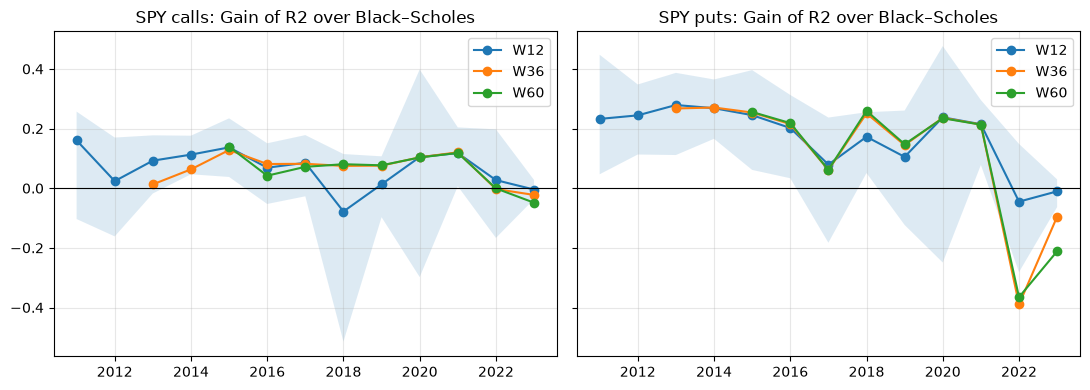

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, cp, nm in zip(axes, "CP", ("calls", "puts")):
    for W in (12, 36, 60):
        x = w[(w.rule == "R2") & (w.base == "R1") & (w.cp == cp) & (w.window == W)].sort_values("year")
        ax.plot(x.year, x.gain, marker="o", label=f"W{W}")
        if W == 12:
            ax.fill_between(x.year, x.lo, x.hi, alpha=0.15)
    ax.axhline(0, color="k", lw=0.8); ax.set_title(f"SPY {nm}: Gain of R2 over Black–Scholes"); ax.legend()
plt.tight_layout()

In [10]:
med = pd.concat([pd.read_csv(R / f"spy/walkforward/{f}.csv").assign(source=f) for f in
                 ("median_yearly_gain", "r5_r8_median_yearly_gain", "r9_r11_median_yearly_gain", "degrees_median_yearly_gain")])
med[med.window == 12].pivot_table(index="rule", columns=["base", "cp"], values="median_yearly_gain").round(3)

base     R1            R2       
cp        C      P      C      P
rule                            
P0    0.068  0.168  0.002 -0.002
P1    0.070  0.157  0.000 -0.004
P2    0.069  0.172  0.000 -0.000
P3    0.073  0.175  0.003  0.002
P4    0.073  0.176  0.004  0.002
P5    0.072  0.176  0.004  0.002
P6    0.072  0.176  0.004  0.003
P7    0.072  0.176  0.004  0.003
P8    0.072  0.176  0.004  0.003
PCV   0.072  0.165  0.003  0.001
R10   0.033  0.145 -0.009 -0.018
R11   0.072  0.176  0.004  0.003
R2    0.069  0.172    NaN    NaN
R5    0.077  0.176  0.006  0.001
R6    0.055  0.203 -0.015 -0.000
R7    0.000  0.114 -0.074 -0.110
R8    0.035  0.133 -0.007 -0.016
R9    0.072  0.176  0.005  0.003

In [11]:
pd.read_csv(R / "spy/walkforward/exdate_by_year.csv").query("pairs == 'ex-date'").round(3)

,year,cp,pairs,n,sessions,G_R2_R1,G_R3_R1,G_R4_R1,share_of_year_R1_sse
1,2011,C,ex-date,1025,3,0.303,0.155,0.211,0.003
3,2011,P,ex-date,1278,3,0.285,0.196,0.221,0.006
5,2012,C,ex-date,1426,4,0.115,-0.080,0.044,0.057
7,2012,P,ex-date,1530,4,0.481,0.398,0.399,0.016
9,2013,C,ex-date,1549,4,0.018,-0.047,-0.008,0.089
11,2013,P,ex-date,1635,4,0.209,0.169,0.182,0.028
13,2014,C,ex-date,1654,4,-0.000,-0.032,-0.006,0.057
15,2014,P,ex-date,1873,4,0.078,0.080,0.087,0.023
17,2015,C,ex-date,1832,4,0.101,-0.315,-0.139,0.030
19,2015,P,ex-date,2167,4,0.681,0.588,0.639,0.018


**Reading.**
- **The same pattern as SPX, clearer for puts.** In the clean years 2011–2014 and 2021, R2's put Gain over Black–Scholes is 0.21–0.28, with intervals above 0. The advantage is gone in 2022–2023, and with the long windows puts go strongly negative in 2022.
- **For SPY calls the fixed 0.9 scaling is worse than Black–Scholes** in most years; R2 and the fitted scaling stay positive.
- **The δ-shape rules (R5, R9, R11, P3 and above) add +0.002 to +0.007 a year** over R2.
- **Ex-date pairs** hold 0.3–9% of a year's squared error, with no systematic loss.